In [3]:
"""
目标：检查标签的均匀性
训练集和测试集
"""
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import jieba
from itertools import chain
import jieba.posseg as pseg
from wordcloud import WordCloud
# import torch


In [4]:
# 数据读取
train_data = pd.read_csv("./data/train.tsv",sep='\t')
dev_data = pd.read_csv("./data/dev.tsv",sep='\t')
print(train_data)

                                               sentence  label
0      早餐不好,服务不到位,晚餐无西餐,早餐晚餐相同,房间条件不好,餐厅不分吸烟区.房间不分有无烟房.      0
1     去的时候 ,酒店大厅和餐厅在装修,感觉大厅有点挤.由于餐厅装修本来该享受的早饭,也没有享受(...      1
2     有很长时间没有在西藏大厦住了，以前去北京在这里住的较多。这次住进来发现换了液晶电视，但网络不...      1
3     非常好的地理位置，住的是豪华海景房，打开窗户就可以看见栈桥和海景。记得很早以前也住过，现在重...      1
4               交通很方便，房间小了一点，但是干净整洁，很有香港的特色，性价比较高，推荐一下哦      1
...                                                 ...    ...
2955  酒店的大堂真的很旧了，房间还可以，早餐的西餐厅比以前的就餐环境好了，以前乱哄哄的，（以前早餐...      1
2956  酒店地理位置不错，交通非常便利，房间整体感觉还可以，只是浴室有些小。酒店提供的早餐不够丰富。...      1
2957  套房面积挺大。最吃惊的是案头上放了文房四宝，差点动了留下到此一游的墨宝的念头，最后还是罢了。...      0
2958               交通不方便不是自己车的话，很不方便的。尤其是在早上叫车他们没有时间观念！      0
2959                            是看了网上评分好才预订的,结果去了后大失所望.      0

[2960 rows x 2 columns]


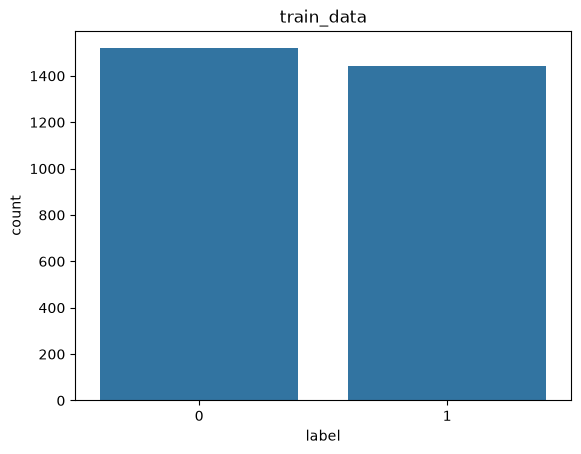

In [5]:
# 数据统计 标签的类别 并且可视化 绘制的是训练集的数据
sns.countplot(x="label",data=train_data)
plt.title("train_data")
plt.show()

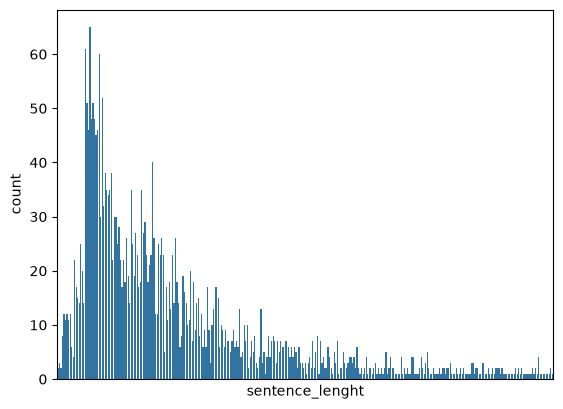

In [10]:
# 使用map将句子长度放入到新的列中
train_data["sentence_lenght"] = list(map(lambda x: len(x), train_data["sentence"]))
sns.countplot(data=train_data, x="sentence_lenght")
plt.xticks([])
plt.show()


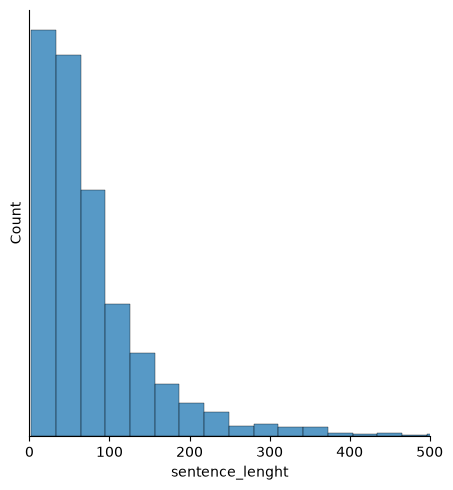

In [11]:
sns.displot(data=train_data, x="sentence_lenght")
plt.xlim(0,500)
plt.yticks([])
plt.show()

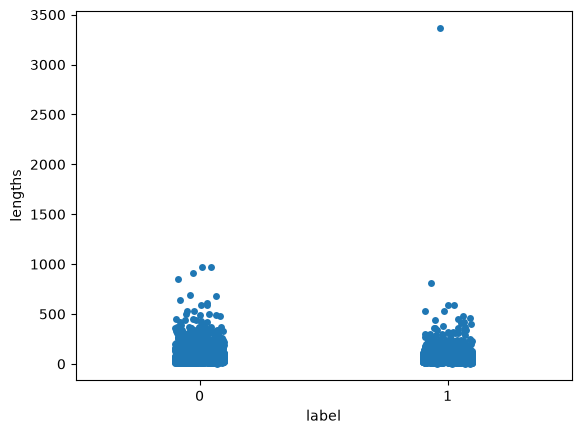

In [6]:
# 使用分割函数画出正负评价的散点图
train_data["lengths"] = list(map(lambda x: len(x), train_data['sentence']))
sns.stripplot(x="label", y="lengths", data=train_data)
plt.show()

In [13]:

# 去重
# word_list = []
# sentences = train_data['sentence'].tolist()
# for sentence in sentences:
#     local_words = jieba.lcut(sentence)
#     for word in local_words:
#         if word not in word_list:
#             word_list.append(word)
# print(len(word_list))
# 另一种写法 使用lcut相当于外面套一层大list需要解包成小list
# 了解chain的用法
word_set = set(chain(*map(lambda x: jieba.lcut(x), train_data['sentence'])))
print(len(word_set))
# 对训练集同理

12162


[pair('早餐', 'n'), pair('不好', 'd'), pair(',', 'x'), pair('服务', 'vn'), pair('不', 'd'), pair('到位', 'v'), pair(',', 'x'), pair('晚餐', 'n'), pair('无', 'v'), pair('西餐', 'n'), pair(',', 'x'), pair('早餐', 'n'), pair('晚餐', 'n'), pair('相同', 'd'), pair(',', 'x'), pair('房间', 'n'), pair('条件', 'n'), pair('不好', 'd'), pair(',', 'x'), pair('餐厅', 'n'), pair('不', 'd'), pair('分', 'v'), pair('吸烟区', 'n'), pair('.', 'x'), pair('房间', 'n'), pair('不分', 'd'), pair('有', 'v'), pair('无烟', 'v'), pair('房', 'j'), pair('.', 'm')]


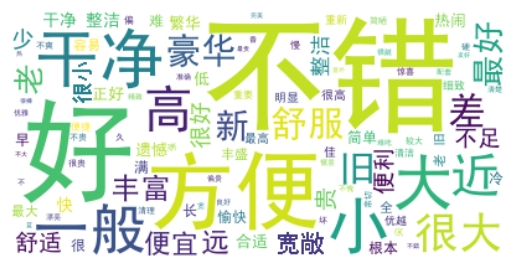

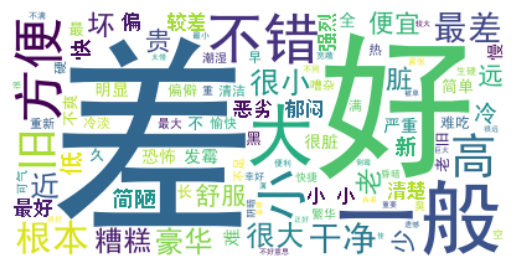

In [ ]:
# 分析形容词的词语
# 获取形容词列表
sentencss = train_data['sentence'].tolist()
print(pseg.lcut(sentencss[0]))
# 正负标签的各自词云
# 找到每个句子里面的形容词
def get_a_list(text):
    return [x.word for x in pseg.lcut(text) if x.flag == "a"]       # x.flag是词性
# 词云生成
def get_word_cloud(keywords):
    # 第一个参数是字体的样式
    wc = WordCloud(font_path="./data/SimHei.ttf", max_words=100, background_color="white")
    # 将列表里面的内容拼接到一起按照空格隔开
    wc.generate(" ".join(keywords))
    plt.figure()
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.show()
# 区分不同的标签数据
p_text = train_data[train_data["label"] == 1]["sentence"]
n_text = train_data[train_data["label"] == 0]["sentence"]
get_word_cloud(chain(*map(get_a_list, p_text)))
get_word_cloud(chain(*map(get_a_list, n_text)))